In [2]:
# imports and global settings
import os
import time
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Lock global random seed
SEED = 42
np.random.seed(SEED)

# 2. Configure Pandas so it never hides columns or truncates tables in Jupyter
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 50)
pd.set_option('display.width', 1000)

# 3. Configure Matplotlib for IEEE Conference Publication Quality (600 DPI)
plt.rcParams['figure.dpi'] = 120
plt.rcParams['savefig.dpi'] = 600
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 10

print("Research environment and random seed initiated.")

Research environment and random seed initiated.


In [3]:
# High-Speed Data Ingestion & Binary/CSV Caching
EXCEL_FILE = "GPS_Data_Simplified_2D_Feature_Map.xlsx"
CACHE_CSV  = "Mendeley_UAS_GPS_Cached.csv"

start_time = time.time()

if os.path.exists(CACHE_CSV):
    print(f"[INFO] Fast cache found! Loading '{CACHE_CSV}'...")
    df_raw = pd.read_csv(CACHE_CSV)
else:
    if not os.path.exists(EXCEL_FILE):
        raise FileNotFoundError(
            f"Could not find '{EXCEL_FILE}' in {os.getcwd()}.\n"
            "Please download 'GPS_Data_Simplified_2D_Feature_Map.xlsx' from "
            "https://data.mendeley.com/datasets/z7dj3yyzt8/3 and place it in this folder."
        )
    print(f"[INFO] Reading '{EXCEL_FILE}' for the first time (takes ~60-90s)...")
    excel_data = pd.read_excel(EXCEL_FILE, sheet_name=None, engine="openpyxl")
    
    # If the workbook has multiple sheets, concatenate them; otherwise grab the single DataFrame
    if isinstance(excel_data, dict):
        print(f" -> Sheets detected: {list(excel_data.keys())}")
        df_raw = pd.concat(excel_data.values(), ignore_index=True)
    else:
        df_raw = excel_data
        
    # Strip any accidental leading/trailing spaces in column names
    df_raw.columns = df_raw.columns.astype(str).str.strip()
    
    # Save the fast CSV cache
    df_raw.to_csv(CACHE_CSV, index=False)
    print(f"[INFO] Created fast cache '{CACHE_CSV}'.")

elapsed = time.time() - start_time
print(f" Loaded {df_raw.shape[0]:,} rows and {df_raw.shape[1]} columns in {elapsed:.2f} seconds.")
display(df_raw.head())

[INFO] Fast cache found! Loading 'Mendeley_UAS_GPS_Cached.csv'...
 Loaded 510,530 rows and 14 columns in 2.69 seconds.


,PRN,DO,PD,RX,TOW,CP,EC,LC,PC,PIP,PQP,TCD,CN0,Output
0,6,1160.671408,-238359.543282,491568.00,491568.000795,-24660.263293,163521.78,170008.81,179294.97,178420.33,-17688.17800,1158.4806,49.412529,0
1,6,1157.827808,-238363.921192,491568.02,491568.020795,-24683.468520,158277.05,160253.09,182106.11,182106.05,158.33333,1160.7948,49.452686,0
2,6,1161.135932,-238368.638615,491568.04,491568.040795,-24706.687357,184442.36,193125.89,208228.02,-205198.30,35391.59000,1157.6909,49.480145,0
3,6,1161.156617,-238373.391775,491568.06,491568.060795,-24729.920039,159812.45,169960.55,187550.72,187543.00,-1701.94400,1161.1343,49.433769,0
4,6,1160.690893,-238378.127066,491568.08,491568.080795,-24753.153999,183557.66,191912.58,208403.50,208330.05,-5532.89990,1161.1759,49.391670,0


In [4]:
# Corrupted Values & Duplicate Removal
initial_row_count = len(df_raw)

# 1. Convert any +inf or -inf values into NaN
df_clean = df_raw.replace([np.inf, -np.inf], np.nan)

# 2. Count and drop NaNs
nan_count = df_clean.isna().sum().sum()
df_clean = df_clean.dropna()
after_nan_count = len(df_clean)

# 3. Drop exact duplicate rows across all columns
df_clean = df_clean.drop_duplicates().reset_index(drop=True)
final_row_count = len(df_clean)

print("=== DATA CORRUPTION AND DUPLICATE REMOVAL SUMMARY  ===")
print(f"Initial Raw Samples        : {initial_row_count:,}")
print(f"Corrupted (NaN/Inf) Dropped: {initial_row_count - after_nan_count:,} (Total NaN cells: {nan_count})")
print(f"Exact Duplicates Dropped   : {after_nan_count - final_row_count:,}")
print(f"Final Clean Samples        : {final_row_count:,}")

=== DATA CORRUPTION AND DUPLICATE REMOVAL SUMMARY  ===
Initial Raw Samples        : 510,530
Corrupted (NaN/Inf) Dropped: 0 (Total NaN cells: 0)
Exact Duplicates Dropped   : 31,218
Final Clean Samples        : 479,312


In [5]:
#Target Class Distribution & Statistical Feature Audit
# Identify the target column (last column in the Mendeley dataset, usually 'Output')
target_col = df_clean.columns[-1]
feature_cols = [c for c in df_clean.columns if c != target_col]

print(f"Target Label Column : '{target_col}'")
print(f"Number of Features  : {len(feature_cols)} -> {feature_cols}\n")

# 1. Class Distribution Table
class_names = {
    0: "0: Authentic (Normal)",
    1: "1: Simplistic Spoofing",
    2: "2: Intermediate Spoofing",
    3: "3: Sophisticated Spoofing"
}

counts = df_clean[target_col].value_counts().sort_index()
pcts   = (df_clean[target_col].value_counts(normalize=True).sort_index() * 100).round(2)

class_dist_df = pd.DataFrame({
    'Attack Category': [class_names.get(k, str(k)) for k in counts.index],
    'Sample Count': counts.values,
    'Percentage (%)': pcts.values
})
print("=== TABLE 1: CLASS DISTRIBUTION ===")
display(class_dist_df)

# 2. Statistical Audit of the 13 Features
stats_df = pd.DataFrame({
    'Dtype': df_clean[feature_cols].dtypes,
    'Unique Values': df_clean[feature_cols].nunique(),
    'Mean': df_clean[feature_cols].mean(),
    'Std Dev': df_clean[feature_cols].std(),
    'Min': df_clean[feature_cols].min(),
    'Max': df_clean[feature_cols].max()
})
print("\n=== TABLE 2: STATISTICAL FEATURE AUDIT ===")
display(stats_df)

Target Label Column : 'Output'
Number of Features  : 13 -> ['PRN', 'DO', 'PD', 'RX', 'TOW', 'CP', 'EC', 'LC', 'PC', 'PIP', 'PQP', 'TCD', 'CN0']

=== TABLE 1: CLASS DISTRIBUTION ===


,Attack Category,Sample Count,Percentage (%)
0,0: Authentic (Normal),366608,76.49
1,1: Simplistic Spoofing,36457,7.61
2,2: Intermediate Spoofing,44232,9.23
3,3: Sophisticated Spoofing,32015,6.68



=== TABLE 2: STATISTICAL FEATURE AUDIT ===


,Dtype,Unique Values,Mean,Std Dev,Min,Max
PRN,int64,19,1.421780e+01,9.134139e+00,2.000000e+00,3.100000e+01
DO,float64,449530,1.353739e+03,2.333767e+03,-4.262755e+03,6.715760e+03
PD,float64,455115,7.438671e+06,9.574086e+06,-6.588428e+06,2.830762e+07
RX,float64,94942,2.897416e+05,1.065784e+05,1.736400e+05,4.920394e+05
TOW,float64,434792,2.897416e+05,1.065784e+05,1.736400e+05,4.920393e+05
CP,float64,461665,-1.276702e+05,2.418345e+05,-1.032332e+06,3.527992e+05
EC,float64,439654,1.078290e+05,3.143055e+04,-1.126115e+04,2.448727e+05
LC,float64,439435,1.077993e+05,3.127736e+04,-1.255751e+04,2.446504e+05
PC,float64,438556,1.193918e+05,3.371527e+04,3.186741e+02,2.714661e+05
PIP,float64,441164,-4.961541e+01,1.219209e+05,-2.707776e+05,2.423611e+05


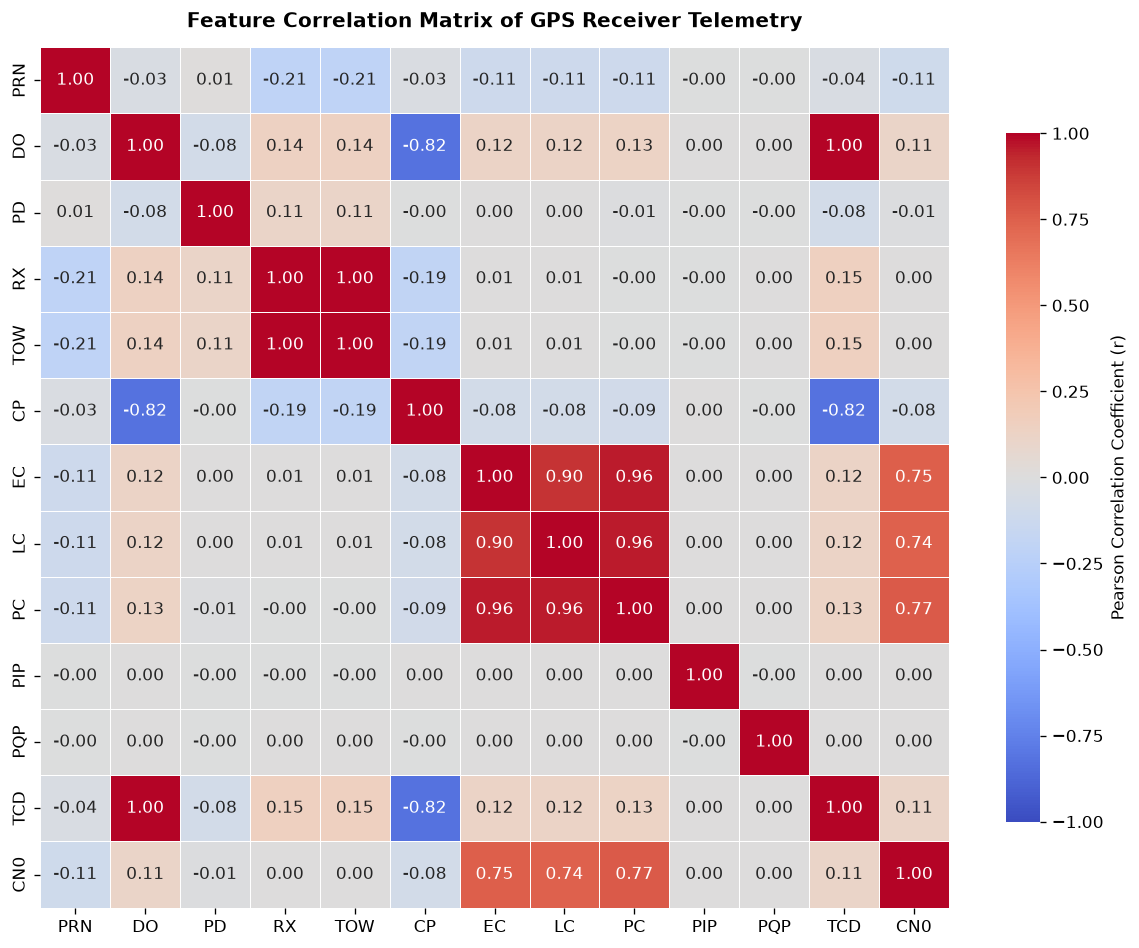

=== HIGHLY COLLINEAR FEATURE PAIRS (|r| > 0.85) ===
 -> DO   and TCD  : r = 0.995854
 -> RX   and TOW  : r = 1.000000
 -> EC   and LC   : r = 0.902903
 -> EC   and PC   : r = 0.959100
 -> LC   and PC   : r = 0.958336


In [6]:
# Generating the Pearson Correlation Matrix
# Compute the Pearson Correlation Matrix on the 13 features
corr_matrix = df_clean[feature_cols].corr(method='pearson')

# Plot IEEE-grade Correlation Heatmap
plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)  # Mask upper triangle for cleanliness
sns.heatmap(
    corr_matrix, 
    annot=True, 
    fmt=".2f", 
    cmap="coolwarm", 
    vmin=-1, vmax=1, 
    linewidths=0.5,
    cbar_kws={"shrink": 0.8, "label": "Pearson Correlation Coefficient (r)"}
)
plt.title("Feature Correlation Matrix of GPS Receiver Telemetry", fontsize=12, fontweight='bold', pad=12)
plt.tight_layout()

# Save 600 DPI figure for your LaTeX Paper
plt.savefig("Fig1_Correlation_Matrix.png", dpi=600)
plt.savefig("Fig1_Correlation_Matrix.pdf", dpi=600)
plt.show()

# Automatically detect and print highly collinear feature pairs (|r| > 0.85)
print("=== HIGHLY COLLINEAR FEATURE PAIRS (|r| > 0.85) ===")
high_corr_pairs = []
for i in range(len(corr_matrix.columns)):
    for j in range(i+1, len(corr_matrix.columns)):
        r_val = corr_matrix.iloc[i, j]
        if abs(r_val) > 0.85:
            f1, f2 = corr_matrix.columns[i], corr_matrix.columns[j]
            high_corr_pairs.append((f1, f2, r_val))
            print(f" -> {f1:<4} and {f2:<4} : r = {r_val:.6f}")

In [7]:
# Auditing Temporal Leakage
# 1. Verify the physical relationship between (RX - TOW) and PD (Pseudorange)
time_diff = df_clean['RX'] - df_clean['TOW']
r_timediff_pd = np.corrcoef(time_diff, df_clean['PD'])[0, 1]
print(f"Correlation between (RX - TOW) and Pseudorange (PD): r = {r_timediff_pd:.6f}")

# 2. Check correlation of each feature with Binary Spoofing Label
y_binary = (df_clean[target_col] > 0).astype(int)
y_multi  = df_clean[target_col].astype(int)

target_corr = df_clean[feature_cols].apply(lambda x: y_binary.corr(x)).sort_values(key=abs, ascending=False)
print("\n=== ABSOLUTE CORRELATION OF FEATURES WITH SPOOFING LABEL ===")
for feat, val in target_corr.items():
    print(f" -> {feat:<4} : r = {val:+.4f}")

Correlation between (RX - TOW) and Pseudorange (PD): r = 0.874364

=== ABSOLUTE CORRELATION OF FEATURES WITH SPOOFING LABEL ===
 -> DO   : r = -0.1328
 -> TCD  : r = -0.1310
 -> CN0  : r = -0.1158
 -> PC   : r = -0.1009
 -> LC   : r = -0.0962
 -> PRN  : r = +0.0962
 -> EC   : r = -0.0928
 -> PD   : r = +0.0847
 -> CP   : r = +0.0791
 -> TOW  : r = -0.0554
 -> RX   : r = -0.0554
 -> PQP  : r = +0.0050
 -> PIP  : r = -0.0010


In [8]:
# Stratified 80/20 Train-Test Split & Standard Scaling
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Define feature matrix X (keeping all 13 features initially for baseline comparison)
X = df_clean[feature_cols].copy()

# Stratified 80/20 Train-Test Split (locks exact class proportions in both train and test)
X_train, X_test, y_train_multi, y_test_multi = train_test_split(
    X, y_multi, 
    test_size=0.20, 
    random_state=SEED, 
    stratify=y_multi
)

# Derive corresponding Binary labels (0 = Authentic, 1 = Spoofed) from the exact same split indices
y_train_bin = (y_train_multi > 0).astype(int)
y_test_bin  = (y_test_multi > 0).astype(int)

# Apply StandardScaler (Fit ONLY on X_train to prevent test leakage!)
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=feature_cols, index=X_train.index)
X_test_scaled  = pd.DataFrame(scaler.transform(X_test), columns=feature_cols, index=X_test.index)

print("=== STRATIFIED 80/20 SPLIT SUMMARY ===")
print(f"Training Set Shape : {X_train_scaled.shape} (80%)")
print(f"Testing Set Shape  : {X_test_scaled.shape}  (20%)")
print("\nTest Set Class Proportions (%) [Must match Table 1 exactly!]:")
print((y_test_multi.value_counts(normalize=True).sort_index() * 100).round(2))

=== STRATIFIED 80/20 SPLIT SUMMARY ===
Training Set Shape : (383449, 13) (80%)
Testing Set Shape  : (95863, 13)  (20%)

Test Set Class Proportions (%) [Must match Table 1 exactly!]:
Output
0    76.49
1     7.61
2     9.23
3     6.68
Name: proportion, dtype: float64


In [9]:
# Universal Publication Metric Evaluator
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, 
    f1_score, roc_auc_score, confusion_matrix, matthews_corrcoef
)

benchmark_results = []
trained_models = {}

def evaluate_and_log_model(name, model, X_tr, y_tr, X_te, y_te):
    print(f"Training {name}...")
    
    # 1. Measure Training Time
    t0 = time.perf_counter()
    model.fit(X_tr, y_tr)
    train_time = time.perf_counter() - t0
    
    # 2. Measure Test Inference Time
    t1 = time.perf_counter()
    y_pred = model.predict(X_te)
    test_time = time.perf_counter() - t1
    latency_us = (test_time / len(X_te)) * 1e6  # Microseconds per sample
    
    # 3. Probabilities & Confusion Matrix
    y_prob = model.predict_proba(X_te)[:, 1] if hasattr(model, "predict_proba") else y_pred
    tn, fp, fn, tp = confusion_matrix(y_te, y_pred).ravel()
    fpr = fp / (fp + tn)
    
    # 4. Log Streamlined Publication Metrics
    metrics = {
        "Model": name,
        "Accuracy (%)": round(accuracy_score(y_te, y_pred) * 100, 3),
        "Precision (%)": round(precision_score(y_te, y_pred) * 100, 3),
        "Recall (%)": round(recall_score(y_te, y_pred) * 100, 3),
        "F1-Score (%)": round(f1_score(y_te, y_pred) * 100, 3),
        "ROC-AUC (%)": round(roc_auc_score(y_te, y_prob) * 100, 3),
        "FPR": round(fpr, 5),
        "MCC": round(matthews_corrcoef(y_te, y_pred), 4),
        "Latency (us)": round(latency_us, 2)
    }
    
    benchmark_results.append(metrics)
    trained_models[name] = model
    print(f" -> Done! Acc: {metrics['Accuracy (%)']}% | F1: {metrics['F1-Score (%)']}% | FPR: {metrics['FPR']} | Latency: {metrics['Latency (us)']} us\n")

print("Streamlined evaluation engine ready.")

Streamlined evaluation engine ready.


In [11]:
%pip install xgboost shap lightgbm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.6/57.6 MB 5.5 MB/s  0:00:10 eta 0:00:010:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 555.9/555.9 kB 6.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.5/3.5 MB 7.7 MB/s  0:00:00a 0:00:010:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 305.1/305.1 MB 6.2 MB/s  0:00:44 eta 0:00:010:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [shap]m━━━━━ 6/7 [shap] [lightgbm]]
Note: you may need to restart the kernel to use updated packages.


In [10]:
# Training and benchmarking
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier

# Reset tracking lists in case cell is re-run
benchmark_results.clear()
trained_models.clear()

# Define the 7 Benchmark Classifiers
models_to_run = [
    ("Logistic Regression", LogisticRegression(max_iter=1000, random_state=SEED, n_jobs=-1)),
    ("SVM", CalibratedClassifierCV(LinearSVC(random_state=SEED, dual="auto"), cv=3, n_jobs=-1)),
    ("KNN", KNeighborsClassifier(n_neighbors=5, algorithm="kd_tree", n_jobs=-1)),
    ("Decision Tree", DecisionTreeClassifier(random_state=SEED)),
    ("Random Forest", RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1)),
    ("Gradient Boosting", HistGradientBoostingClassifier(max_iter=100, random_state=SEED)),
    ("XGBoost", XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=6, tree_method="hist", random_state=SEED, n_jobs=-1, eval_metric="logloss"))
]

print("=== STARTING 7-MODEL BENCHMARK ON 13 FEATURES ===\n")
for model_name, clf in models_to_run:
    evaluate_and_log_model(model_name, clf, X_train_scaled, y_train_bin, X_test_scaled, y_test_bin)

# Convert results into a clean DataFrame sorted by F1-Score
results_df = pd.DataFrame(benchmark_results).sort_values(by="F1-Score (%)", ascending=False).reset_index(drop=True)

print("=== TABLE 3: BASELINE 13-FEATURE PERFORMANCE COMPARISON ===")
display(results_df)

# Save table to CSV for easy LaTeX conversion later
results_df.to_csv("Table3_Baseline_7Models_Results.csv", index=False)

=== STARTING 7-MODEL BENCHMARK ON 13 FEATURES ===

Training Logistic Regression...
 -> Done! Acc: 76.22% | F1: 0.792% | FPR: 0.00472 | Latency: 0.12 us

Training SVM...
 -> Done! Acc: 76.223% | F1: 0.818% | FPR: 0.00472 | Latency: 0.72 us

Training KNN...
 -> Done! Acc: 86.382% | F1: 69.83% | FPR: 0.07668 | Latency: 194.52 us

Training Decision Tree...
 -> Done! Acc: 92.459% | F1: 83.934% | FPR: 0.04872 | Latency: 0.31 us

Training Random Forest...
 -> Done! Acc: 91.115% | F1: 81.129% | FPR: 0.05843 | Latency: 5.79 us

Training Gradient Boosting...
 -> Done! Acc: 94.627% | F1: 88.318% | FPR: 0.02838 | Latency: 4.26 us

Training XGBoost...
 -> Done! Acc: 94.572% | F1: 87.612% | FPR: 0.01447 | Latency: 1.04 us

=== TABLE 3: BASELINE 13-FEATURE PERFORMANCE COMPARISON ===


,Model,Accuracy (%),Precision (%),Recall (%),F1-Score (%),ROC-AUC (%),FPR,MCC,Latency (us)
0,Gradient Boosting,94.627,90.344,86.380,88.318,99.208,0.02838,0.8487,4.26
1,XGBoost,94.572,94.548,81.625,87.612,99.175,0.01447,0.8453,1.04
2,Decision Tree,92.459,84.093,83.776,83.934,89.749,0.04872,0.7901,0.31
3,Random Forest,91.115,81.038,81.221,81.129,98.567,0.05843,0.7532,5.79
4,KNN,86.382,72.880,67.025,69.830,93.059,0.07668,0.6114,194.52
5,SVM,76.223,21.364,0.417,0.818,65.083,0.00472,-0.0034,0.72
6,Logistic Regression,76.220,20.824,0.404,0.792,64.977,0.00472,-0.0043,0.12


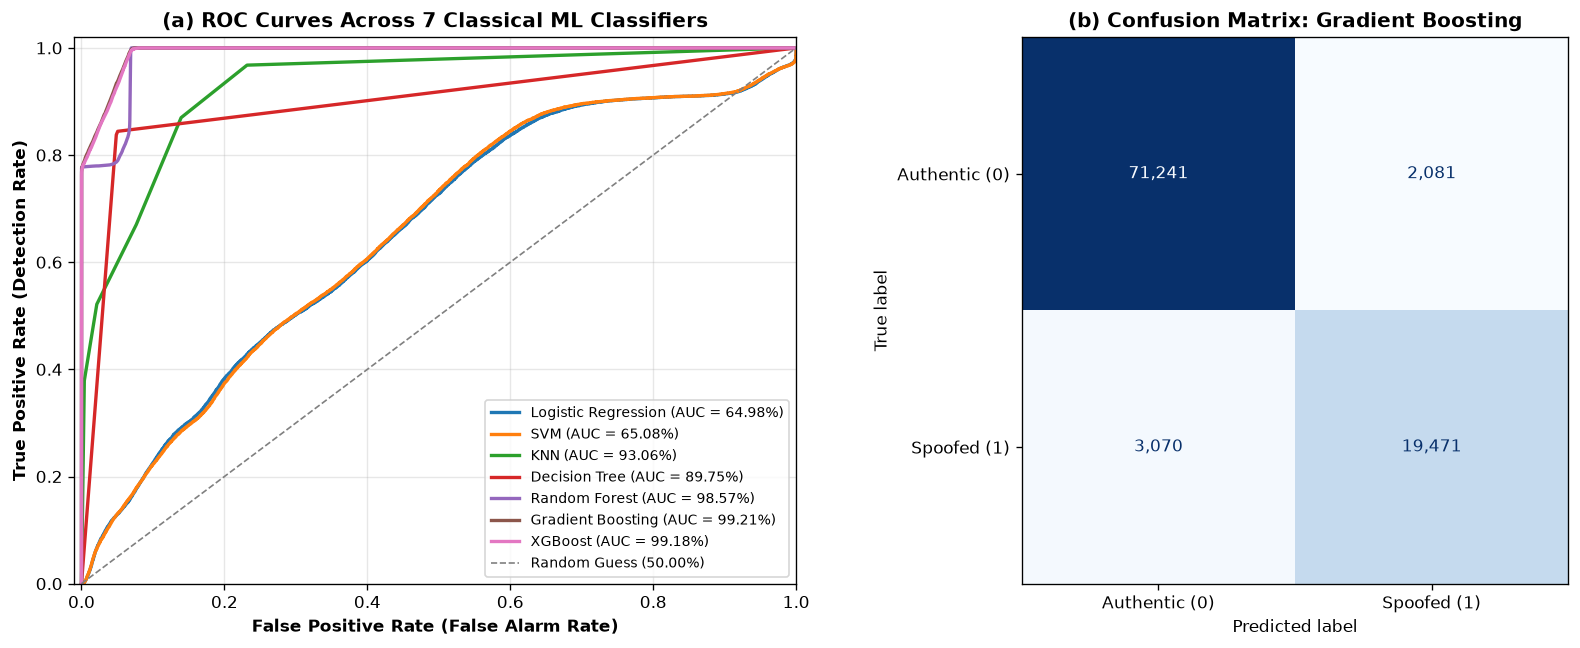

[SUCCESS] Generated and saved Figure 2 using 'Gradient Boosting'!


In [11]:
# Confusion matrix
from sklearn.metrics import roc_curve, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# 1. Left Subplot: Comparative ROC Curves for All 7 Models
ax_roc = axes[0]
for name, model in trained_models.items():
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test_scaled)[:, 1]
    else:
        y_prob = model.predict(X_test_scaled)
        
    fpr_curve, tpr_curve, _ = roc_curve(y_test_bin, y_prob)
    auc_val = roc_auc_score(y_test_bin, y_prob) * 100
    ax_roc.plot(fpr_curve, tpr_curve, lw=2, label=f"{name} (AUC = {auc_val:.2f}%)")

ax_roc.plot([0, 1], [0, 1], color="gray", linestyle="--", lw=1, label="Random Guess (50.00%)")
ax_roc.set_xlim([-0.01, 1.0])
ax_roc.set_ylim([0.0, 1.02])
ax_roc.set_xlabel("False Positive Rate (False Alarm Rate)", fontweight="bold")
ax_roc.set_ylabel("True Positive Rate (Detection Rate)", fontweight="bold")
ax_roc.set_title("(a) ROC Curves Across 7 Classical ML Classifiers", fontweight="bold")
ax_roc.legend(loc="lower right", fontsize=8.5)
ax_roc.grid(alpha=0.3)

# 2. Right Subplot: Confusion Matrix of Top Ensemble Model (Gradient Boosting or XGBoost)
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

ConfusionMatrixDisplay.from_estimator(
    best_model, X_test_scaled, y_test_bin,
    display_labels=["Authentic (0)", "Spoofed (1)"],
    cmap="Blues", values_format=",d", ax=axes[1], colorbar=False
)
axes[1].set_title(f"(b) Confusion Matrix: {best_model_name}", fontweight="bold")

plt.tight_layout()
plt.savefig("Fig2_ROC_and_ConfusionMatrix.png", dpi=600)
plt.savefig("Fig2_ROC_and_ConfusionMatrix.pdf", dpi=600)
plt.show()

print(f"[SUCCESS] Generated and saved Figure 2 using '{best_model_name}'!")

[INFO] Initializing TreeExplainer for SHAP analysis...


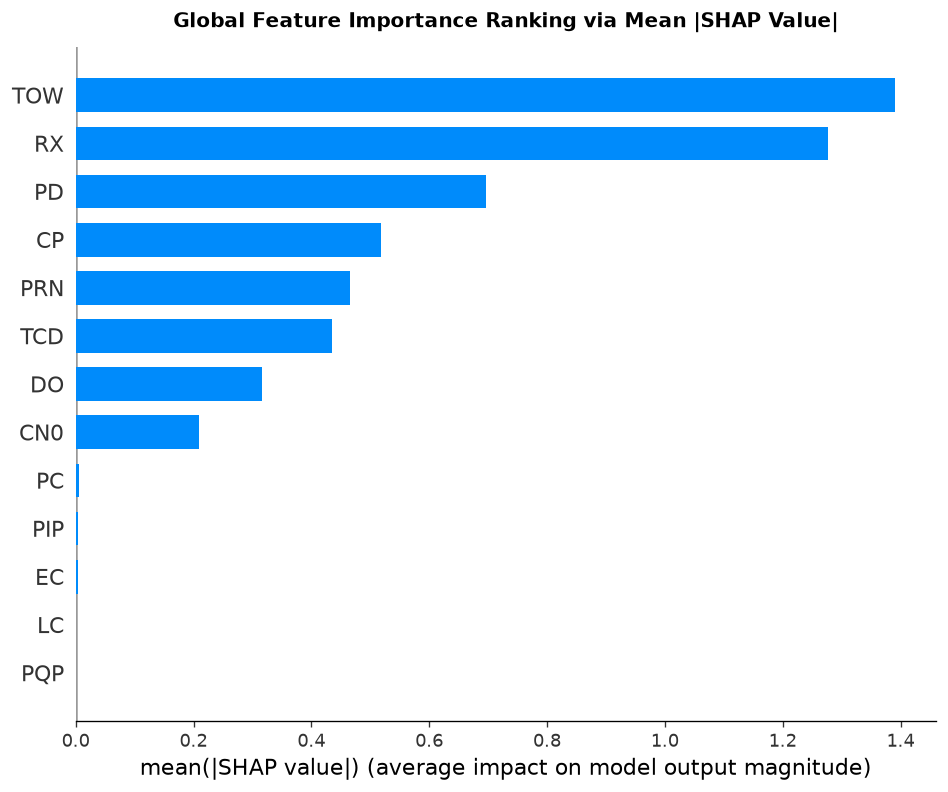

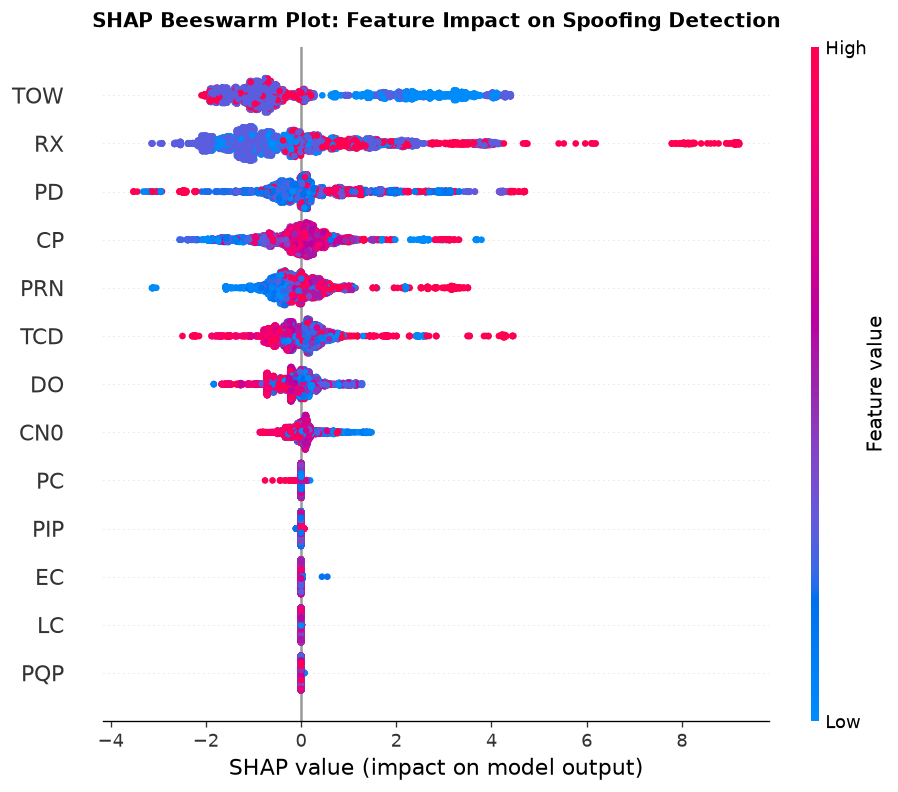

[SUCCESS] SHAP explainability analysis complete! Figures 3 and 4 saved.


In [17]:
# SHAP and Feature optimisation
import shap

print("[INFO] Initializing TreeExplainer for SHAP analysis...")
# Use the best trained tree model from our benchmark (e.g., Gradient Boosting or XGBoost)
best_clf = trained_models["Gradient Boosting"]

# Initialize TreeExplainer (optimized for tree ensembles)
explainer = shap.TreeExplainer(best_clf)

# Compute SHAP values on a stratified test subset (e.g., 5,000 samples for fast rendering)
X_test_sample = X_test_scaled.sample(n=5000, random_state=SEED)
shap_values = explainer.shap_values(X_test_sample)

# If multi-class or binary outputs format adjustment
if isinstance(shap_values, list):
    shap_vals_to_plot = shap_values[1] # Positive attack class
else:
    shap_vals_to_plot = shap_values

# Plot 1: Global Feature Importance Bar Plot (Mean Absolute SHAP)
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_vals_to_plot, X_test_sample, plot_type="bar", show=False)
plt.title("Global Feature Importance Ranking via Mean |SHAP Value|", fontsize=12, fontweight='bold', pad=12)
plt.tight_layout()
plt.savefig("Fig3_SHAP_Global_Bar.png", dpi=600)
plt.savefig("Fig3_SHAP_Global_Bar.pdf", dpi=600)
plt.show()

# Plot 2: SHAP Beeswarm Summary Plot (Feature Impact & Directionality)
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_vals_to_plot, X_test_sample, show=False)
plt.title("SHAP Beeswarm Plot: Feature Impact on Spoofing Detection", fontsize=12, fontweight='bold', pad=12)
plt.tight_layout()
plt.savefig("Fig4_SHAP_Beeswarm.png", dpi=600)
plt.savefig("Fig4_SHAP_Beeswarm.pdf", dpi=600)
plt.show()

print("[SUCCESS] SHAP explainability analysis complete! Figures 3 and 4 saved.")

 Original features (13): ['PRN', 'DO', 'PD', 'RX', 'TOW', 'CP', 'EC', 'LC', 'PC', 'PIP', 'PQP', 'TCD', 'CN0']
 Optimized feature set (10): ['PRN', 'DO', 'PD', 'CP', 'EC', 'LC', 'PC', 'PIP', 'PQP', 'CN0']

 Re-training models on leakage-free physical features...
 -> Optimized Gradient Boosting | Accuracy: 94.53% | F1-Score: 88.16%
 -> Optimized XGBoost | Accuracy: 94.48% | F1-Score: 87.62%


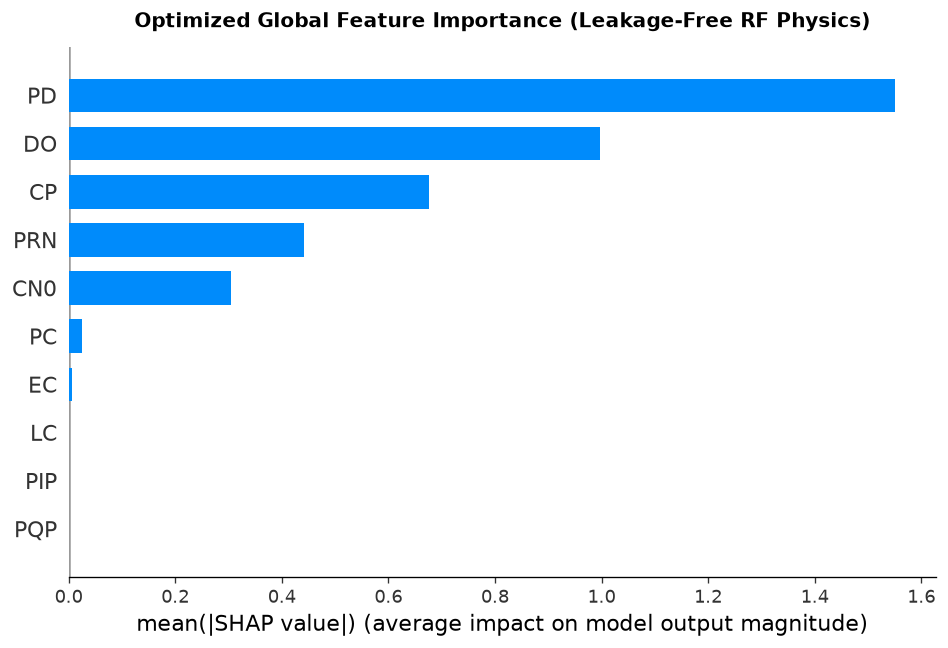

 Feature ablation complete! Clean physics-only SHAP plot generated.


In [12]:
# Prunning features 
# 1. Define feature pruning list (Dropping leakage clocks TOW, RX, and redundant TCD)
features_to_drop = ['TOW', 'RX', 'TCD']
optimized_feature_cols = [c for c in feature_cols if c not in features_to_drop]

print(f" Original features ({len(feature_cols)}): {feature_cols}")
print(f" Optimized feature set ({len(optimized_feature_cols)}): {optimized_feature_cols}")

# 2. Re-slice training and testing matrices
X_train_opt = X_train_scaled[optimized_feature_cols]
X_test_opt  = X_test_scaled[optimized_feature_cols]

# 3. Re-train Gradient Boosting and XGBoost on optimized features
from sklearn.ensemble import HistGradientBoostingClassifier
from xgboost import XGBClassifier
import shap

print("\n Re-training models on leakage-free physical features...")
opt_models = {
    "Optimized Gradient Boosting": HistGradientBoostingClassifier(max_iter=100, random_state=SEED),
    "Optimized XGBoost": XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=6, tree_method="hist", random_state=SEED, n_jobs=-1, eval_metric="logloss")
}

opt_results = []
for name, clf in opt_models.items():
    clf.fit(X_train_opt, y_train_bin)
    preds = clf.predict(X_test_opt)
    acc = accuracy_score(y_test_bin, preds) * 100
    f1  = f1_score(y_test_bin, preds) * 100
    print(f" -> {name} | Accuracy: {acc:.2f}% | F1-Score: {f1:.2f}%")

# 4. Generate Clean SHAP Plot for Optimized XGBoost
best_opt_model = opt_models["Optimized XGBoost"]
opt_explainer = shap.TreeExplainer(best_opt_model)
X_test_sample_opt = X_test_opt.sample(n=5000, random_state=SEED)
shap_vals_opt = opt_explainer.shap_values(X_test_sample_opt)

if isinstance(shap_vals_opt, list):
    shap_vals_opt_plot = shap_vals_opt[1]
else:
    shap_vals_opt_plot = shap_vals_opt

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_vals_opt_plot, X_test_sample_opt, plot_type="bar", show=False)
plt.title("Optimized Global Feature Importance (Leakage-Free RF Physics)", fontsize=12, fontweight='bold', pad=12)
plt.tight_layout()
plt.savefig("Fig5_SHAP_Optimized_Bar.png", dpi=600)
plt.savefig("Fig5_SHAP_Optimized_Bar.pdf", dpi=600)
plt.show()

print(" Feature ablation complete! Clean physics-only SHAP plot generated.")